# Camera-conditioned latent world model for video person re-identification

**Research question.** Does forecasting an ordered tracklet's unseen future improve cross-camera retrieval on unseen identities, especially when some query frames are occluded?

A tracklet is an ordered sequence of cropped detections from one camera. The notebook uses the first part of a sampled clip to build a latent state. It trains a small recurrent model to roll that state forward within the same camera, then to predict how the identity embedding could appear in a specified gallery camera. At retrieval time it combines appearance similarity and both directional predictions. Predicted uncertainty reduces the influence of a forecast when the model is less certain.

## Run on Kaggle

1. Import this `.ipynb` through **File → Import Notebook**. Use the default `RUN_PROFILE = "smoke"` and **Run All** for a small, offline check. This profile generates artificial tracklets and works on CPU.
2. For real data, obtain the [MARS release](https://zheng-lab-anu.github.io/Project/project_mars.html) and the [official split files](https://github.com/liangzheng06/MARS-evaluation/tree/master/info). The authors list the dataset package as 6.26 GB. Use the dataset according to its access terms.
3. Put `bbox_train` and `bbox_test` (or the individual `bbox_train.zip` and `bbox_test.zip` archives) beside the `info` folder. Attach the files through **Add Input**. If the original release is one outer archive, unpack it once to get the two folders or archives. The notebook streams images and never unpacks the individual archives.
4. Enable a **GPU** accelerator such as a T4. Change `RUN_PROFILE` to `"pilot"` for a subset run, or `"research"` for the full official test set. Set `MARS_ROOT` to the attached folder if auto-discovery finds zero or multiple matches. Restart the session and **Run All**.

```text
MARS/
  bbox_train/ or bbox_train.zip
  bbox_test/  or bbox_test.zip
  info/
    train_name.txt
    test_name.txt
    tracks_train_info.mat
    tracks_test_info.mat
    query_IDX.mat
```

The notebook uses packages in Kaggle's Python image and loads no external weights. Each profile reports exactly which split it used. Synthetic and pilot scores are pipeline checks. Use the research profile for full-split results. This implementation studies a task-specific, observational latent world model. Camera labels specify observation context. There are no control actions or cross-camera travel-time assumptions.

## Related work and the proposed test

| Paper | Connection |
| --- | --- |
| [Yin et al., MPCCL, Pattern Recognition 2022](https://doi.org/10.1016/j.patcog.2022.108710) | Direct person ReID precedent for multiview predictive coding and contrastive learning. Its predictive targets are different views of image-derived representations. |
| [Real-Time People Re-Identification and Tracking for Autonomous Platforms Using a Trajectory Prediction-Based Approach, Sensors 2022](https://doi.org/10.3390/s22155856) | Predicts future positions and uses them with an online tracker to improve identity association. |
| [Assran, Bardes et al., V-JEPA 2, first posted 2025](https://arxiv.org/abs/2506.09985) | Method precedent for predicting video latents and learning an action-conditioned world model for robot planning. |

**Proposed contribution.** Train a single recurrent state on true within-tracklet future latents and on identity-matched cross-camera latents. At test time, score a query–gallery pair using an uncertainty-weighted residual over appearance similarity, in both directions. Within-camera targets come from later frames. Cross-camera targets come from a separate observation of the same training identity, with unknown temporal order.

The central control uses the same trained frame encoder, recurrent architecture, camera inputs, paired observations and ranking rule, with the future loss disabled. Additional controls isolate variance weighting, camera conditioning, bidirectional scoring and input order. The forecast diagnostic compares multi-step error against persistence of the last observed frame. These comparisons test a narrower claim than an assertion of firstness or state-of-the-art performance.

**Outputs.** CSV metrics and training curves, query-level results and paired bootstrap intervals, forecast errors, plots, run settings and PyTorch checkpoints. In Kaggle they appear under `/kaggle/working/camera_world_reid/`.


In [1]:
# 1. Imports and run settings
import io
import json
import math
import os
import random
import time
import zipfile
from collections import defaultdict, deque
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image, ImageDraw
from scipy.io import loadmat
from torch.utils.data import DataLoader, Dataset, Sampler

RUN_PROFILE = "smoke"  # "smoke", "pilot", or "research"
MARS_ROOT = ""         # e.g. "/kaggle/input/datasets/owner/mars/MARS"
SEED = 42
SPLIT_SEED = 1729      # Keep fixed when comparing training seeds.
NUM_WORKERS = 0       # Optional: try 2 for extracted MARS on Kaggle.

@dataclass(frozen=True)
class Settings:
    height: int
    width: int
    embed_dim: int
    hidden_dim: int
    encoder_width: int
    identities_per_batch: int
    frame_epochs: int
    head_epochs: int
    max_steps: int | None
    train_id_limit: int | None
    test_id_limit: int | None
    train_tracks_per_camera: int | None
    extract_batch: int
    context: int = 4
    horizon: int = 3
    stride: int = 2
    view_loss_weight: float = 0.50
    forecast_loss_weight: float = 0.75
    prefix_occlusion_probability: float = 0.30
    variance_reference: float = 0.20

PROFILES = {
    "smoke": Settings(48, 24, 32, 48, 12, 4, 2, 3, 5, None, None, None, 16),
    "pilot": Settings(96, 48, 96, 128, 24, 8, 5, 8, 75, 104, 64, 3, 32),
    "research": Settings(128, 64, 128, 192, 24, 12, 18, 24, None, None, None, None, 32),
}
cfg = PROFILES[RUN_PROFILE]
device = torch.device("cpu")
if torch.cuda.is_available():
    try:
        torch.zeros(1, device="cuda").add_(1)
        torch.cuda.synchronize()
    except RuntimeError as error:
        print(f"CUDA probe failed. The notebook will use CPU. Choose a compatible GPU such as a T4.\n{error}")
    else:
        device = torch.device("cuda")
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.set_float32_matmul_precision("high" if device.type == "cuda" else "highest")
torch.backends.cudnn.benchmark = False

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
kaggle = Path("/kaggle/working").is_dir()
default_out = Path("/kaggle/working" if kaggle else ".") / "camera_world_reid" / RUN_PROFILE / f"seed_{SEED}"
out_dir = Path(os.environ.get("REID_OUTPUT_DIR", str(default_out))).resolve()
out_dir.mkdir(parents=True, exist_ok=True)

print(f"Profile: {RUN_PROFILE} | device: {device} | torch: {torch.__version__}")
print(f"Outputs: {out_dir}")
if RUN_PROFILE != "smoke" and device.type != "cuda":
    print("CPU selected. Enable a GPU in Kaggle for real-data training.")


Profile: smoke | device: cuda | torch: 2.11.0+cu130
Outputs: /kaggle/working/camera_world_reid/smoke/seed_42


In [2]:
# 2. Read MARS metadata or construct synthetic tracklets.
@dataclass(frozen=True)
class Tracklet:
    split: str
    row: int
    pid: int
    cam: int
    frames: tuple

    @property
    def key(self):
        return f"{self.split}-{self.row:06d}"

INFO_FILES = (
    "train_name.txt", "test_name.txt", "tracks_train_info.mat",
    "tracks_test_info.mat", "query_IDX.mat",
)

def split_input(root, split):
    folder = root / f"bbox_{split}"
    archive = root / f"bbox_{split}.zip"
    if folder.is_dir():
        return folder
    if archive.is_file():
        return archive
    raise FileNotFoundError(f"Missing {folder.name}/ or {archive.name} in {root}")

def is_mars_root(path):
    if not all((path / "info" / name).is_file() for name in INFO_FILES):
        return False
    return all(
        (path / f"bbox_{split}").is_dir() or (path / f"bbox_{split}.zip").is_file()
        for split in ("train", "test")
    )

def find_mars_root(explicit):
    if explicit:
        root = Path(explicit).expanduser()
        if is_mars_root(root):
            return root
        raise FileNotFoundError(f"{root} is missing one or more inputs in the setup diagram.")
    pending = deque([(Path("/kaggle/input"), 0)])
    matches = []
    while pending:
        candidate, depth = pending.popleft()
        if not candidate.is_dir():
            continue
        if is_mars_root(candidate):
            matches.append(candidate)
            continue
        if depth < 5:
            pending.extend(
                (child, depth + 1) for child in sorted(candidate.iterdir())
                if child.is_dir() and child.name not in {"bbox_train", "bbox_test", "info"}
            )
    if len(matches) == 1:
        return matches[0]
    detail = ", ".join(str(path) for path in matches) or "no matching folder"
    raise FileNotFoundError(f"MARS auto-discovery found {detail}. Check the layout and set MARS_ROOT.")

def read_mat_integer(path, key):
    arrays = loadmat(path, variable_names=[key])
    if key not in arrays:
        raise ValueError(f"{path.name} does not contain '{key}'.")
    data = arrays[key]
    if not np.isfinite(data).all() or not np.equal(data, np.rint(data)).all():
        raise ValueError(f"{path.name} contains non-integer or non-finite values.")
    return data.astype(np.int64)

def read_mars_tracks(info, split):
    name_file = info / f"{split}_name.txt"
    names = [line.strip() for line in name_file.read_text(encoding="utf-8-sig").splitlines()]
    rows = read_mat_integer(info / f"tracks_{split}_info.mat", f"track_{split}_info")
    if rows.ndim != 2 or rows.shape[1] != 4:
        raise ValueError(f"Expected four columns in the official {split} tracklet table.")
    tracks = []
    for row, (first, last, pid, cam) in enumerate(rows):
        if not 1 <= first <= last <= len(names) or not 1 <= cam <= 6:
            raise ValueError(f"Invalid MARS frame bounds or camera in {split} row {row + 1}.")
        filenames = tuple(names[first - 1:last])
        if not filenames[0] or not filenames[-1]:
            raise ValueError(f"Empty frame filename in {split} row {row + 1}.")
        tracks.append(Tracklet(split, row, int(pid), int(cam - 1), filenames))
    return tracks

def synthetic_tracks(split, pids, seed):
    rng = np.random.default_rng(seed)
    tracks = []
    for pid in pids:
        for cam in range(3):
            for repeat in range(2):
                row = len(tracks)
                length = int(rng.integers(8, 23))
                tracks.append(Tracklet(split, row, pid, cam, tuple(range(length))))
    return tracks

def group_by_identity_and_camera(tracks):
    groups = defaultdict(lambda: defaultdict(list))
    for index, track in enumerate(tracks):
        if track.pid > 0:
            groups[track.pid][track.cam].append(index)
    return {pid: dict(by_cam) for pid, by_cam in groups.items()}

def choose_ids(pids, count, rng):
    pids = sorted(pids)
    if count is None or len(pids) <= count:
        return set(pids)
    return set(rng.choice(pids, count, replace=False).tolist())

def make_val_queries(tracks):
    groups = group_by_identity_and_camera(tracks)
    return [
        tracks[indices[0]]
        for by_camera in groups.values() if len(by_camera) > 1
        for indices in by_camera.values()
    ]

def limit_train_tracks(tracks, limit, rng):
    if limit is None:
        return tracks
    keep = []
    for by_camera in group_by_identity_and_camera(tracks).values():
        for indices in by_camera.values():
            selected = rng.choice(indices, min(limit, len(indices)), replace=False)
            keep.extend(selected.tolist())
    return [tracks[index] for index in sorted(keep)]

rng = np.random.default_rng(SPLIT_SEED)
source_paths = {}
if RUN_PROFILE == "smoke":
    train_original = synthetic_tracks("train", range(1, 17), SPLIT_SEED)
    test_original = synthetic_tracks("test", range(101, 109), SPLIT_SEED + 1)
    official_query = [track for track in test_original if track.cam == 0 and track.row % 2 == 0]
    camera_count = 3
else:
    root = find_mars_root(MARS_ROOT)
    print(f"MARS root: {root}")
    source_paths = {split: split_input(root, split) for split in ("train", "test")}
    train_original = read_mars_tracks(root / "info", "train")
    test_original = read_mars_tracks(root / "info", "test")
    query_rows = read_mat_integer(root / "info" / "query_IDX.mat", "query_IDX").ravel() - 1
    if len(query_rows) == 0 or query_rows.min() < 0 or query_rows.max() >= len(test_original):
        raise ValueError("Official query indices are absent or outside the test tracklet table.")
    if len(set(query_rows.tolist())) != len(query_rows):
        raise ValueError("Official query indices contain duplicates.")
    official_query = [test_original[index] for index in query_rows if test_original[index].pid > 0]
    camera_count = 6

eligible = {
    pid for pid, by_cam in group_by_identity_and_camera(train_original).items()
    if len(by_cam) >= 2
}
if len(eligible) < 4:
    raise ValueError("The training metadata needs at least four cross-camera identities.")
val_n = min(max(4, round(0.12 * len(eligible))), max(2, len(eligible) - 2))
val_ids = choose_ids(eligible, val_n, rng)
train_ids = choose_ids(eligible - val_ids, cfg.train_id_limit, rng)

train_tracks = limit_train_tracks(
    [track for track in train_original if track.pid in train_ids],
    cfg.train_tracks_per_camera,
    rng,
)
val_gallery = [track for track in train_original if track.pid in val_ids]
val_query = make_val_queries(val_gallery)

test_pids = choose_ids({track.pid for track in official_query}, cfg.test_id_limit, rng)
if cfg.test_id_limit is None:
    test_gallery = [track for track in test_original if track.pid >= 0]
else:
    distractors = [track for track in test_original if track.pid == 0]
    keep_distractors = set(rng.choice(
        len(distractors), min(320, len(distractors)), replace=False
    ).tolist())
    keep_rows = {distractors[index].row for index in keep_distractors}
    test_gallery = [
        track for track in test_original
        if track.pid in test_pids or (track.pid == 0 and track.row in keep_rows)
    ]
test_query = [track for track in official_query if track.pid in test_pids]
test_all_ids = {track.pid for track in test_gallery if track.pid > 0}
assert train_ids.isdisjoint(val_ids | test_all_ids)
assert val_ids.isdisjoint(test_all_ids)
if not all((train_tracks, val_query, val_gallery, test_query, test_gallery)):
    raise ValueError("An empty training, validation, or test partition was found.")

split_name = {
    "smoke": "artificial tracklets",
    "pilot": "MARS pilot subset",
    "research": "MARS official test query indices and all non-junk test tracklets",
}[RUN_PROFILE]
if any(path.is_file() for path in source_paths.values()) and NUM_WORKERS > 0:
    print("Each worker opens its own ZIP index. Reduce NUM_WORKERS to 0 if RAM is limited.")
class_to_index = {pid: index for index, pid in enumerate(sorted(train_ids))}
display(pd.DataFrame([
    ("train", len(train_tracks), len(train_ids)),
    ("validation query", len(val_query), len(val_ids)),
    ("validation gallery", len(val_gallery), len(val_ids)),
    ("test query", len(test_query), len(test_pids)),
    ("test gallery", len(test_gallery), len(test_all_ids)),
], columns=["split", "tracklets", "positive identities"]))
print(f"Protocol: {split_name} | DataLoader workers: {NUM_WORKERS}")


,split,tracklets,positive identities
0,train,72,12
1,validation query,12,4
2,validation gallery,24,4
3,test query,8,8
4,test gallery,48,8


Protocol: artificial tracklets | DataLoader workers: 0


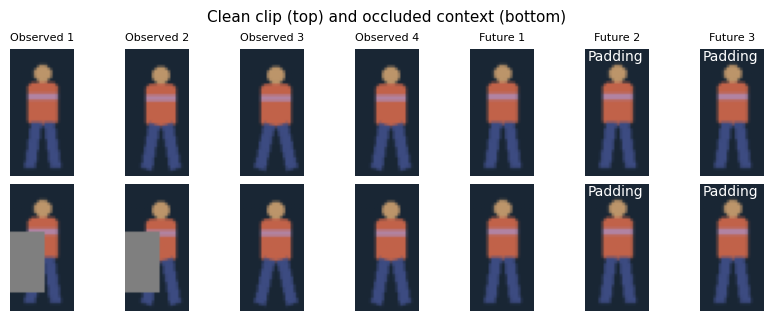

In [3]:
# 3. Read only the sampled crops, preserve their order, and mask padding.
class FrameReader:
    def __init__(self, paths):
        self.paths = paths
        self._process = None
        self._archives = {}
        self._prefixes = {}

    def close(self):
        for handle in self._archives.values():
            handle.close()
        self._archives.clear()
        self._prefixes.clear()

    def _read_from_zip(self, path, relative):
        if os.getpid() != self._process:
            self.close()
            self._process = os.getpid()
        if path not in self._archives:
            handle = zipfile.ZipFile(path)
            self._archives[path] = handle
            sample = next(
                (entry.filename for entry in handle.filelist
                 if entry.filename.lower().endswith((".jpg", ".jpeg"))
                 and not entry.filename.startswith("__MACOSX/")),
                None,
            )
            if sample is None:
                raise ValueError(f"{path.name} contains no JPEG crops.")
            head, _, filename = sample.rpartition("/")
            prefix, _, pid_dir = head.rpartition("/")
            if pid_dir != filename[:4]:
                raise ValueError(f"Unexpected crop path in {path.name}: {sample}")
            self._prefixes[path] = prefix + "/" if prefix else ""
        handle = self._archives[path]
        return handle.read(self._prefixes[path] + relative)

    def read(self, track, frame_index):
        frame = track.frames[frame_index]
        if not self.paths:
            return self.synthetic_image(track, int(frame))
        folder = self.paths[track.split]
        relative = f"{frame[:4]}/{frame}"
        try:
            if folder.is_dir():
                with Image.open(folder / relative) as image:
                    return image.convert("RGB")
            with Image.open(io.BytesIO(self._read_from_zip(folder, relative))) as image:
                return image.convert("RGB")
        except (KeyError, OSError, zipfile.BadZipFile) as error:
            raise RuntimeError(f"Could not read {relative} from {folder} for {track.key}.") from error

    @staticmethod
    def synthetic_image(track, frame):
        rng = np.random.default_rng(track.pid)
        shirt = tuple(rng.integers(55, 220, 3).tolist())
        trousers = tuple(rng.integers(20, 155, 3).tolist())
        stripe = tuple(rng.integers(120, 248, 3).tolist())
        background = [(25, 38, 52), (58, 42, 32), (31, 53, 40)][track.cam]
        image = Image.new("RGB", (40, 80), background)
        draw = ImageDraw.Draw(image)
        wave = math.sin((frame + track.row * 0.27) * (0.22 + 0.03 * (track.pid % 5)))
        x = 20 + round(3 * wave) + track.cam - 1
        y = 9 + round(2 * wave)
        draw.ellipse((x - 5, y, x + 5, y + 10), fill=(188, 149, 106))
        draw.rounded_rectangle((x - 9, y + 11, x + 9, y + 37), 3, fill=shirt)
        draw.rectangle((x - 9, y + 16 + track.pid % 6, x + 9, y + 19 + track.pid % 6), fill=stripe)
        leg = round(4 * wave)
        draw.line((x - 4, y + 36, x - 6 - leg, y + 64), fill=trousers, width=7)
        draw.line((x + 4, y + 36, x + 6 + leg, y + 64), fill=trousers, width=7)
        return image

def sampled_indices(length, count, stride, fraction):
    last_start = max(0, length - (1 + (count - 1) * stride))
    start = random.randint(0, last_start) if fraction is None else round(fraction * last_start)
    indices = start + stride * np.arange(count)
    return np.minimum(indices, length - 1), indices < length

def occlude_prefix(images, valid, seed):
    """Hide a contiguous body region in up to half the valid context frames."""
    rng = np.random.default_rng(seed)
    copies = images.clone()
    candidates = np.flatnonzero(valid[:cfg.context])
    if len(candidates) == 0:
        return copies
    count = min(len(candidates), max(1, cfg.context // 2))
    chosen = rng.choice(candidates, count, replace=False)
    height, width = copies.shape[-2:]
    h, w = max(1, round(0.48 * height)), max(1, round(0.55 * width))
    top = int(rng.integers(height // 5, height - h + 1))
    left = int(rng.integers(0, width - w + 1))
    copies[chosen, :, top:top + h, left:left + w] = 0.5
    return copies

class ClipDataset(Dataset):
    def __init__(self, tracks, count, fraction, train=False, with_occlusion=False):
        self.tracks = tracks
        self.count = count
        self.fraction = fraction
        self.train = train
        self.with_occlusion = with_occlusion
        self.reader = FrameReader(source_paths)

    def __len__(self):
        return len(self.tracks)

    def __getitem__(self, index):
        track = self.tracks[index]
        frame_ids, mask = sampled_indices(len(track.frames), self.count, cfg.stride, self.fraction)
        flip = self.train and random.random() < 0.5
        gain = random.uniform(0.85, 1.15) if self.train else 1.0
        frames = {}
        for frame_id in np.unique(frame_ids):
            image = self.reader.read(track, int(frame_id)).resize(
                (cfg.width, cfg.height), resample=Image.Resampling.BILINEAR
            )
            if flip:
                image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            frames[frame_id] = np.asarray(image, dtype=np.uint8)
        images = torch.from_numpy(np.stack([frames[frame_id] for frame_id in frame_ids]))
        images = images.permute(0, 3, 1, 2).float().div_(255.0).mul_(gain).clamp_(0.0, 1.0)
        record = {"images": images, "mask": torch.from_numpy(mask), "index": index}
        if self.with_occlusion:
            corruption_seed = SPLIT_SEED + 97 * track.row + (1_000_003 if track.split == "test" else 0)
            record["occluded"] = occlude_prefix(images, mask, corruption_seed)
        return record

def make_loader(dataset, *, batch_size=None, batch_sampler=None, seed=SEED):
    options = {
        "num_workers": NUM_WORKERS,
        "pin_memory": device.type == "cuda",
        "generator": torch.Generator().manual_seed(seed),
    }
    if batch_sampler is not None:
        return DataLoader(dataset, batch_sampler=batch_sampler, **options)
    return DataLoader(dataset, batch_size=batch_size, shuffle=False, **options)

n_frames = cfg.context + cfg.horizon
preview_dataset = ClipDataset(train_tracks, n_frames, 0.5, with_occlusion=True)
example = preview_dataset[0]
preview_dataset.reader.close()
assert example["images"].shape == (n_frames, 3, cfg.height, cfg.width)
fig, axes = plt.subplots(2, n_frames, figsize=(n_frames * 1.15, 3.1), layout="constrained")
for col in range(n_frames):
    title = f"Observed {col + 1}" if col < cfg.context else f"Future {col - cfg.context + 1}"
    axes[0, col].set_title(title, fontsize=8)
    for row, key in enumerate(("images", "occluded")):
        axes[row, col].imshow(example[key][col].permute(1, 2, 0).numpy())
        axes[row, col].axis("off")
        if not bool(example["mask"][col]):
            axes[row, col].text(0.04, 0.91, "Padding", color="white", transform=axes[row, col].transAxes)
fig.suptitle("Clean clip (top) and occluded context (bottom)", fontsize=11)
plt.show()
plt.close(fig)


## 4–6. Train a shared appearance encoder and cache frame latents

A compact residual CNN maps each crop to a unit-length vector. The mean of the valid context embeddings, renormalized, is the appearance baseline. It uses the same frames at retrieval as the world model does. Supervised identity classification and cross-camera triplet loss train the encoder on training identities. The encoder then stays frozen across all configurations. Every training tracklet contributes up to two temporal windows. Every evaluation tracklet uses one deterministic window.


In [4]:
# 4. Define the batch sampler and shared appearance encoder.
class CameraPairBatchSampler(Sampler):
    def __init__(self, tracks, seed):
        groups = group_by_identity_and_camera(tracks)
        self.groups = {pid: cams for pid, cams in groups.items() if len(cams) >= 2}
        self.pids = np.array(sorted(self.groups), dtype=np.int64)
        self.p = min(cfg.identities_per_batch, len(self.pids))
        if self.p < 2:
            raise ValueError("Paired training requires at least two cross-camera identities.")
        self.steps = math.ceil(len(tracks) / (2 * self.p))
        if cfg.max_steps is not None:
            self.steps = min(self.steps, cfg.max_steps)
        self.seed = seed
        self.epoch = 0

    def __len__(self):
        return self.steps

    def __iter__(self):
        rng = np.random.default_rng(self.seed + 1009 * self.epoch)
        for _ in range(self.steps):
            batch = []
            for pid in rng.choice(self.pids, self.p, replace=False):
                groups = self.groups[int(pid)]
                cams = rng.choice(list(groups), 2, replace=False)
                batch.extend(int(rng.choice(groups[int(cam)])) for cam in cams)
            yield batch

def paired_index(batch_size, tensor_device):
    if batch_size % 2:
        raise ValueError("Every training item must have one paired item in its batch.")
    return torch.arange(batch_size, device=tensor_device) ^ 1

def masked_anchor(features, mask):
    summed = (features * mask.unsqueeze(-1)).sum(dim=1)
    return F.normalize(summed, dim=-1)

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
            nn.GroupNorm(4, out_channels),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.GroupNorm(4, out_channels),
        )
        self.skip = nn.Identity() if (stride == 1 and in_channels == out_channels) else nn.Conv2d(
            in_channels, out_channels, 1, stride, bias=False
        )

    def forward(self, images):
        return F.silu(self.body(images) + self.skip(images))

class FrameEncoder(nn.Module):
    def __init__(self, width, embed_dim, num_labels):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, width, 5, 2, 2, bias=False),
            nn.GroupNorm(4, width),
            nn.SiLU(),
            ResidualBlock(width, width, 1),
            ResidualBlock(width, 2 * width, 2),
            ResidualBlock(2 * width, 3 * width, 2),
            ResidualBlock(3 * width, 4 * width, 2),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(4 * width, embed_dim),
            nn.LayerNorm(embed_dim),
        )
        self.classifier = nn.Linear(embed_dim, num_labels, bias=False)

    def forward(self, clips):
        batch, steps = clips.shape[:2]
        images = clips.flatten(0, 1).mul(2.0).sub(1.0)
        embedding = F.normalize(self.features(images).float(), dim=-1)
        return embedding.reshape(batch, steps, -1)

def appearance_objective(encoder, clips, mask, labels):
    features = encoder(clips)
    anchor = masked_anchor(features, mask)
    logits = 12.0 * F.linear(anchor, F.normalize(encoder.classifier.weight.float(), dim=-1))
    classification = F.cross_entropy(logits, labels)
    distances = 1.0 - (anchor @ anchor.T)
    paired = paired_index(len(anchor), anchor.device)
    positive_distance = distances[torch.arange(len(anchor), device=anchor.device), paired]
    negatives = labels[:, None] != labels[None, :]
    negative_distance = distances.masked_fill(~negatives, float("inf")).amin(dim=1)
    triplet = F.relu(positive_distance - negative_distance + 0.20).mean()
    return classification + 0.60 * triplet, classification, triplet


In [5]:
# 5. Train the frame encoder.
def atomic_checkpoint(data, filename):
    path = out_dir / filename
    temporary = path.with_suffix(".tmp")
    torch.save(data, temporary)
    temporary.replace(path)

frame_model = FrameEncoder(cfg.encoder_width, cfg.embed_dim, len(class_to_index)).to(device)
frame_dataset = ClipDataset(train_tracks, cfg.context, fraction=None, train=True)
frame_sampler = CameraPairBatchSampler(train_tracks, SEED + 1200)
frame_loader = make_loader(frame_dataset, batch_sampler=frame_sampler, seed=SEED + 3)
train_class_indices = torch.tensor([class_to_index[track.pid] for track in train_tracks])

frame_optimizer = torch.optim.AdamW(frame_model.parameters(), lr=8e-4, weight_decay=1e-4)
frame_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    frame_optimizer, T_max=cfg.frame_epochs, eta_min=8e-5
)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
frame_history = []
for epoch in range(cfg.frame_epochs):
    frame_model.train()
    frame_sampler.epoch = epoch
    total = np.zeros(3, dtype=np.float64)
    for batch in frame_loader:
        clips = batch["images"].to(device, non_blocking=use_amp)
        mask = batch["mask"].to(device, non_blocking=use_amp)
        targets = train_class_indices[batch["index"]].to(device)
        frame_optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp, dtype=torch.float16):
            loss, classification, triplet = appearance_objective(frame_model, clips, mask, targets)
        if not bool(torch.isfinite(loss)):
            raise FloatingPointError("Non-finite appearance loss.")
        scaler.scale(loss).backward()
        scaler.unscale_(frame_optimizer)
        nn.utils.clip_grad_norm_(frame_model.parameters(), max_norm=5.0)
        scaler.step(frame_optimizer)
        scaler.update()
        total += torch.stack((loss, classification, triplet)).detach().float().cpu().numpy()
    frame_scheduler.step()
    averages = total / len(frame_loader)
    frame_history.append((epoch + 1, *averages.tolist()))
    print(f"Encoder epoch {epoch + 1:02d}/{cfg.frame_epochs:02d} | loss {averages[0]:.4f}")
frame_dataset.reader.close()
frame_model.eval().requires_grad_(False)

atomic_checkpoint({
    "model_state": frame_model.state_dict(),
    "settings": asdict(cfg),
    "class_to_index": class_to_index,
}, "frame_encoder.pt")
pd.DataFrame(
    frame_history, columns=["epoch", "total_loss", "classification_loss", "triplet_loss"]
).to_csv(out_dir / "appearance_history.csv", index=False)


Encoder epoch 01/02 | loss 4.1467
Encoder epoch 02/02 | loss 3.2655


In [6]:
# 6. Cache frozen clean latents and occluded context latents.
@dataclass
class Features:
    clean: torch.Tensor
    occluded: torch.Tensor
    valid: torch.Tensor
    cameras: torch.Tensor
    pids: torch.Tensor
    keys: tuple

    def take(self, indices):
        indices = torch.as_tensor(indices, dtype=torch.long)
        return Features(
            self.clean[indices], self.occluded[indices], self.valid[indices],
            self.cameras[indices], self.pids[indices],
            tuple(self.keys[i] for i in indices.tolist()),
        )

@torch.no_grad()
def cache_latents(tracks, fraction, label, report=True):
    dataset = ClipDataset(tracks, n_frames, fraction, with_occlusion=True)
    loader = make_loader(dataset, batch_size=cfg.extract_batch)
    clean = torch.empty((len(tracks), n_frames, cfg.embed_dim), dtype=torch.float32)
    occluded = torch.empty((len(tracks), cfg.context, cfg.embed_dim), dtype=torch.float32)
    valid = torch.empty((len(tracks), n_frames), dtype=torch.bool)
    start = time.monotonic()
    for batch in loader:
        index = batch["index"]
        images = batch["images"].to(device, non_blocking=use_amp)
        corrupted = batch["occluded"][:, :cfg.context].to(device, non_blocking=use_amp)
        with torch.autocast(device_type=device.type, enabled=use_amp, dtype=torch.float16):
            clean[index] = frame_model(images).float().cpu()
            occluded[index] = frame_model(corrupted).float().cpu()
        valid[index] = batch["mask"]
    dataset.reader.close()
    if not bool(torch.isfinite(clean).all() & torch.isfinite(occluded).all()):
        raise FloatingPointError(f"Non-finite features in {label}.")
    if report:
        future_fraction = valid[:, cfg.context:].any(1).float().mean().item()
        print(f"{label}: {len(tracks):,} clips | with future frames {future_fraction:.1%} "
              f"| {time.monotonic() - start:.1f}s")
    return Features(
        clean, occluded, valid,
        torch.tensor([track.cam for track in tracks], dtype=torch.long),
        torch.tensor([track.pid for track in tracks], dtype=torch.long),
        tuple(track.key for track in tracks),
    )

def build_eval_features(gallery_tracks, query_tracks, label):
    gallery = cache_latents(gallery_tracks, 0.5, label)
    lookup = {key: index for index, key in enumerate(gallery.keys)}
    query = gallery.take([lookup[track.key] for track in query_tracks])
    return query, gallery

cache_a = cache_latents(train_tracks, 0.15, "Train windows A")
cache_b = cache_latents(train_tracks, 0.75, "Train windows B")
train_feat = Features(
    torch.cat((cache_a.clean, cache_b.clean)),
    torch.cat((cache_a.occluded, cache_b.occluded)),
    torch.cat((cache_a.valid, cache_b.valid)),
    torch.cat((cache_a.cameras, cache_b.cameras)),
    torch.cat((cache_a.pids, cache_b.pids)),
    cache_a.keys + cache_b.keys,
)
del cache_a, cache_b
if RUN_PROFILE != "smoke" and not bool(train_feat.valid[:, cfg.context:].any()):
    raise ValueError("There are no valid training futures. Check clip length and stride.")
val_q, val_g = build_eval_features(val_gallery, val_query, "Validation gallery")
# Cache the test features after validation has fixed model and scoring choices.


Train windows A: 72 clips | with future frames 94.4% | 0.3s
Train windows B: 72 clips | with future frames 94.4% | 0.2s
Validation gallery: 24 clips | with future frames 91.7% | 0.1s


## 7–8. Learn within-tracklet dynamics and cross-camera observations

Write $a(x)$ for the unit-normalized average of the observed frame latents. A GRU reads the valid context in order. A recurrent transition then predicts the next $H$ frame latents, feeding its own predictions back as inputs. A camera-conditioned head maps the last rolled state and $a(x)$ to a predicted latent mean $\mu_{x\to c}$ and log variance $\log v_{x\to c}$ for a tracklet seen in camera $c$.

For a unit-length target $z$, the training objective uses the scaled isotropic Gaussian-form loss

$$
\ell(z,\mu,v)=\frac{1-z^\mathsf{T}\mu}{v}+\tfrac12\log v.
$$

The within-tracklet targets are genuine later frame embeddings. Across cameras, the target is the appearance anchor of a paired training tracklet of the same identity. Identity-mismatched tracks from the destination camera are contrastive negatives. Camera metadata and the input prefix are the only information used to generate a forecast. Random occlusion of the input prefix during training exposes the model to varying observation quality while keeping the target latents clean.

The full model combines the contrastive loss, the positive cross-camera predictive loss and the multi-step future loss. The view-only control has identical layers and zero weight on the temporal loss. The camera-blind control removes source and destination camera embeddings, and uses the same paired loss and training data. The variance is a learned latent error scale, with a held-out diagnostic for how closely it tracks forecast errors.


In [7]:
# 7. Define the recurrent world model and the paired prediction losses.
def last_valid(features, mask):
    indices = torch.arange(mask.shape[1], device=mask.device)
    last = (indices * mask).amax(dim=1)
    return features[torch.arange(len(features), device=features.device), last]

class LatentWorldModel(nn.Module):
    def __init__(self, camera_context):
        super().__init__()
        self.camera_context = camera_context
        self.camera = nn.Embedding(camera_count, 16)
        self.observe = nn.GRUCell(cfg.embed_dim + 16, cfg.hidden_dim)
        self.transition = nn.GRUCell(cfg.embed_dim + 16, cfg.hidden_dim)
        self.future_stats = nn.Linear(cfg.hidden_dim, cfg.embed_dim + 1)
        self.view_stats = nn.Sequential(
            nn.Linear(cfg.hidden_dim + cfg.embed_dim + 32, cfg.hidden_dim),
            nn.LayerNorm(cfg.hidden_dim),
            nn.SiLU(),
            nn.Linear(cfg.hidden_dim, cfg.embed_dim + 1),
        )
        for layer in (self.future_stats, self.view_stats[-1]):
            nn.init.normal_(layer.weight, std=0.01)
            nn.init.zeros_(layer.bias)
            nn.init.constant_(layer.bias[-1:], math.log(cfg.variance_reference))

    def cam_features(self, cameras):
        features = self.camera(cameras)
        if not self.camera_context:
            return torch.zeros_like(features)
        return features

    @staticmethod
    def get_stats(parameters, anchor):
        residual, log_var = parameters[:, :-1], parameters[:, -1]
        mean = F.normalize(anchor + 0.5 * residual, dim=-1)
        return mean, log_var.clamp(min=-5.0, max=0.70)

    def roll(self, prefix, valid, cameras):
        anchor = masked_anchor(prefix, valid)
        camera = self.cam_features(cameras)
        state = prefix.new_zeros(len(prefix), cfg.hidden_dim)
        for index in range(prefix.shape[1]):
            candidate = self.observe(torch.cat((prefix[:, index], camera), dim=1), state)
            state = torch.where(valid[:, index, None], candidate, state)
        previous = last_valid(prefix, valid)
        means, log_vars = [], []
        for _ in range(cfg.horizon):
            state = self.transition(torch.cat((previous, camera), dim=1), state)
            previous, log_var = self.get_stats(self.future_stats(state), anchor)
            means.append(previous)
            log_vars.append(log_var)
        return anchor, state, torch.stack(means, dim=1), torch.stack(log_vars, dim=1)

    def predict_view(self, state, anchor, source, target):
        features = torch.cat(
            (state, anchor, self.cam_features(source), self.cam_features(target)), dim=1
        )
        return self.get_stats(self.view_stats(features), anchor)

def angular_error(mean, target):
    return (1.0 - (mean * target).sum(dim=-1)).clamp_min(0.0)

def predictive_loss(mean, log_var, target):
    return angular_error(mean, target) * torch.exp(-log_var) + 0.5 * log_var

def view_and_future_loss(model, features, index, use_corruption, future_weight):
    clean = features.clean[index].to(device)
    corrupt = features.occluded[index].to(device)
    valid = features.valid[index].to(device)
    cameras = features.cameras[index].to(device)
    pids = features.pids[index].to(device)
    pair = paired_index(len(clean), device)

    clean_prefix = clean[:, :cfg.context]
    prefix = torch.where(use_corruption[:, None, None], corrupt, clean_prefix)
    prefix_valid = valid[:, :cfg.context]
    anchor, state, future, future_log_var = model.roll(prefix, prefix_valid, cameras)
    targets = masked_anchor(clean_prefix, prefix_valid)
    target_cameras = cameras[pair]

    mean, log_var = model.predict_view(state, anchor, cameras, target_cameras)
    view_nll = predictive_loss(mean, log_var, targets[pair]).mean()

    # Each row's distractors come from its queried destination camera.
    same_destination = target_cameras[:, None] == cameras[None, :]
    different_pid = pids[:, None] != pids[None, :]
    paired_entry = torch.arange(len(pids), device=device)[None, :] == pair[:, None]
    valid_candidates = same_destination & (different_pid | paired_entry)
    logits = (mean @ targets.T) / 0.08
    view_contrast = F.cross_entropy(logits.masked_fill(~valid_candidates, -1e4), pair)

    future_mask = valid[:, cfg.context:]
    forecast = predictive_loss(future, future_log_var, clean[:, cfg.context:])
    forecast_nll = (forecast * future_mask).sum() / future_mask.sum().clamp_min(1)
    loss = view_contrast + cfg.view_loss_weight * view_nll + future_weight * forecast_nll
    return loss, view_contrast, view_nll, forecast_nll


In [8]:
# 8. Train the full model and the two architectural controls.
def fit_world_model(name, camera_context, future_weight):
    seed_all(SEED + 2000)
    model = LatentWorldModel(camera_context=camera_context).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=9e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=cfg.head_epochs, eta_min=1e-4
    )
    sampler = CameraPairBatchSampler(train_tracks * 2, SEED + 2010)
    noise_generator = torch.Generator().manual_seed(SEED + 2020)
    history = []
    for epoch in range(cfg.head_epochs):
        sampler.epoch = epoch
        means = np.zeros(4, dtype=np.float64)
        for batch in sampler:
            index = torch.tensor(batch, dtype=torch.long)
            corruption = torch.rand(len(index), generator=noise_generator)
            use_corruption = (corruption < cfg.prefix_occlusion_probability).to(device)
            optimizer.zero_grad(set_to_none=True)
            losses = view_and_future_loss(model, train_feat, index, use_corruption, future_weight)
            if not bool(torch.isfinite(torch.stack(losses)).all()):
                raise FloatingPointError(f"Non-finite training loss in {name}.")
            losses[0].backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            means += torch.stack(losses).detach().cpu().numpy()
        scheduler.step()
        means /= len(sampler)
        history.append((name, epoch + 1, *means.tolist()))
        print(f"{name} epoch {epoch + 1:02d}/{cfg.head_epochs:02d} | loss {means[0]:.4f}")

    atomic_checkpoint({
        "model_state": model.state_dict(),
        "settings": asdict(cfg),
        "camera_context": camera_context,
        "camera_count": camera_count,
        "future_weight": future_weight,
    }, f"{name}.pt")
    return model.eval().requires_grad_(False), history

world_models = {}
world_history = []
for name, camera_context, future_weight in (
    ("world_model", True, cfg.forecast_loss_weight),
    ("view_only", True, 0.0),
    ("camera_blind", False, cfg.forecast_loss_weight),
):
    model, rows = fit_world_model(name, camera_context, future_weight)
    world_models[name] = model
    world_history.extend(rows)

pd.DataFrame(
    world_history,
    columns=["model", "epoch", "total_loss", "view_contrast", "view_nll", "forecast_nll"],
).to_csv(out_dir / "world_history.csv", index=False)


world_model epoch 01/03 | loss -0.0603
world_model epoch 02/03 | loss -0.1142
world_model epoch 03/03 | loss -0.1887
view_only epoch 01/03 | loss 0.4948
view_only epoch 02/03 | loss 0.4599
view_only epoch 03/03 | loss 0.3944
camera_blind epoch 01/03 | loss -0.0655
camera_blind epoch 02/03 | loss -0.1233
camera_blind epoch 03/03 | loss -0.2000


## 9–11. Tune on held-out identities and evaluate retrieval

The baseline score is cosine similarity $b=a(q)^\mathsf{T}a(g)$. The world model forecasts the gallery latent from the query and the query latent from the gallery, conditioned on the other camera in each direction. For the forward direction use

$$
d(q\to g)=\frac{v_0}{v_0+v_{q\to c_g}}
\big(\mu_{q\to c_g}^\mathsf{T}a(g)-b\big).
$$

The final score is $b+\alpha[d(q\to g)+d(g\to q)]/2$. The correction is applied to different-camera candidates. The no-gate control sets the variance weight to one. The forward-only control uses $b+\alpha d(q\to g)$. $\alpha$ is selected separately for each model and ablation using mean clean and occluded validation mAP. Zero is a valid choice. The reversed-order diagnostic uses the full model's chosen $\alpha$.

The MARS research evaluation uses the authors' query indices and the full test set as gallery. It removes junk and same-identity, same-camera matches, keeps distractors, and reports Rank-1/5/10 and mAP. mAP uses the standard mean of precisions at relevant ranks. The output also includes trapezoidal mAP for comparison with the original MATLAB implementation. The query occlusion stress test hides a rectangle in selected observed frames and preserves the gallery. Every ranking starts from the same number and placement of observed frames.


In [9]:
# 9. Define retrieval scores and exact query-level metrics.
@dataclass
class RetrievalState:
    anchors: torch.Tensor
    cameras: torch.Tensor
    view_means: torch.Tensor | None = None
    view_vars: torch.Tensor | None = None

@torch.no_grad()
def represent(data, model=None, condition="clean", reverse=False):
    prefix = data.clean[:, :cfg.context] if condition == "clean" else data.occluded
    mask = data.valid[:, :cfg.context]
    anchors = masked_anchor(prefix, mask)
    if model is None:
        return RetrievalState(anchors, data.cameras)
    if reverse:
        prefix, mask = prefix.flip(1), mask.flip(1)

    means, variances = [], []
    destination = torch.arange(camera_count, device=device)
    for start in range(0, len(prefix), 384):
        take = slice(start, start + 384)
        cameras = data.cameras[take].to(device)
        _, state, _, _ = model.roll(prefix[take].to(device), mask[take].to(device), cameras)
        anchor = anchors[take].to(device)
        mean, log_var = model.predict_view(
            state.repeat_interleave(camera_count, dim=0),
            anchor.repeat_interleave(camera_count, dim=0),
            cameras.repeat_interleave(camera_count),
            destination.repeat(len(anchor)),
        )
        means.append(mean.reshape(len(anchor), camera_count, -1).cpu())
        variances.append(log_var.exp().reshape(len(anchor), camera_count).cpu())
    return RetrievalState(anchors, data.cameras, torch.cat(means), torch.cat(variances))

@torch.no_grad()
def score_chunks(query, gallery, use_gate, bidirectional, query_batch=64):
    gallery_anchor = gallery.anchors.to(device)
    gallery_groups = {
        cam: torch.where(gallery.cameras == cam)[0].to(device)
        for cam in gallery.cameras.unique().tolist()
    }
    use_world = query.view_means is not None
    if use_world and bidirectional:
        gallery_means = gallery.view_means.to(device)
        gallery_vars = gallery.view_vars.to(device)
    for start in range(0, len(query.anchors), query_batch):
        take = slice(start, start + query_batch)
        query_anchor = query.anchors[take].to(device)
        base = query_anchor @ gallery_anchor.T
        correction = torch.zeros_like(base)
        if use_world:
            query_means = query.view_means[take].to(device)
            query_vars = query.view_vars[take].to(device)
            query_cameras = query.cameras[take]
            for source in query_cameras.unique().tolist():
                q_index = torch.where(query_cameras == source)[0].to(device)
                for target, g_index in gallery_groups.items():
                    if source == target:
                        continue
                    pos = (q_index[:, None], g_index[None, :])
                    forward = query_means[q_index, target] @ gallery_anchor[g_index].T - base[pos]
                    if use_gate:
                        forward *= (cfg.variance_reference / (
                            cfg.variance_reference + query_vars[q_index, target]
                        ))[:, None]
                    if not bidirectional:
                        correction[pos] = forward
                        continue
                    backward = query_anchor[q_index] @ gallery_means[g_index, source].T - base[pos]
                    if use_gate:
                        backward *= (cfg.variance_reference / (
                            cfg.variance_reference + gallery_vars[g_index, source]
                        ))[None, :]
                    correction[pos] = 0.5 * (forward + backward)
        yield start, base.cpu().numpy(), correction.cpu().numpy()

def average_precisions(relevant_ranks):
    hit_counts = np.arange(1, len(relevant_ranks) + 1, dtype=np.float64)
    precision = hit_counts / relevant_ranks
    previous = np.ones_like(precision)
    np.divide(hit_counts - 1, relevant_ranks - 1, out=previous, where=relevant_ranks > 1)
    return float(precision.mean()), float(0.5 * (precision + previous).mean())

def evaluate_rankings(query_data, gallery_data, query_repr, gallery_repr, alphas, use_gate, bidirectional):
    query_pids = query_data.pids.numpy()
    query_cameras = query_data.cameras.numpy()
    gallery_pids = gallery_data.pids.numpy()
    gallery_cameras = gallery_data.cameras.numpy()
    result = {alpha: [] for alpha in alphas}
    for start, baseline, delta in score_chunks(query_repr, gallery_repr, use_gate, bidirectional):
        for row, (base, correction) in enumerate(zip(baseline, delta)):
            q = start + row
            pid, cam = int(query_pids[q]), int(query_cameras[q])
            same_identity = gallery_pids == pid
            keep = (gallery_pids >= 0) & ~(same_identity & (gallery_cameras == cam))
            valid_positive = same_identity[keep]
            if not valid_positive.any():
                continue
            for alpha in alphas:
                scores = base[keep] + alpha * correction[keep]
                ranking = np.argsort(-scores, kind="stable")
                relevant_ranks = np.flatnonzero(valid_positive[ranking]) + 1
                ap, ap_trapezoidal = average_precisions(relevant_ranks)
                result[alpha].append((query_data.keys[q], pid, int(relevant_ranks[0]), ap, ap_trapezoidal))
    columns = ["query_key", "query_pid", "first_rank", "ap", "ap_trapezoidal"]
    records = {alpha: pd.DataFrame(rows, columns=columns) for alpha, rows in result.items()}
    if not records[alphas[0]].shape[0]:
        raise ValueError("None of the queries has a different-camera positive in its gallery.")
    return records

def summarize_retrieval(rows, total_queries):
    return {
        "mAP": rows["ap"].mean(),
        "mAP_trapezoidal": rows["ap_trapezoidal"].mean(),
        "rank1": (rows["first_rank"] <= 1).mean(),
        "rank5": (rows["first_rank"] <= 5).mean(),
        "rank10": (rows["first_rank"] <= 10).mean(),
        "valid_queries": len(rows),
        "skipped_without_positive": total_queries - len(rows),
    }


In [10]:
# 10. Freeze scoring hyperparameters using only validation identities.
@dataclass(frozen=True)
class Experiment:
    name: str
    model: str | None
    use_gate: bool = True
    bidirectional: bool = True
    reverse: bool = False

experiments = [
    Experiment("Appearance cosine", None),
    Experiment("World model", "world_model"),
    Experiment("View-only control", "view_only"),
    Experiment("World model without variance gate", "world_model", use_gate=False),
    Experiment("World model with forward scoring", "world_model", bidirectional=False),
    Experiment("Camera-blind control", "camera_blind"),
    Experiment("World model with reversed context", "world_model", reverse=True),
]
conditions = ("clean", "occluded")
alpha_grid = (0.0, 0.25, 0.5, 0.75, 1.0, 1.5)
selected_alpha = {"Appearance cosine": 0.0}
validation_rows = []
for trial in experiments[1:]:
    if trial.reverse:
        selected_alpha[trial.name] = selected_alpha["World model"]
        continue
    model = world_models[trial.model]
    gallery_repr = represent(val_g, model)
    maps = defaultdict(list)
    for condition in conditions:
        query_repr = represent(val_q, model, condition)
        metrics = evaluate_rankings(
            val_q, val_g, query_repr, gallery_repr, alpha_grid, trial.use_gate, trial.bidirectional
        )
        for alpha in alpha_grid:
            score = metrics[alpha]["ap"].mean()
            maps[alpha].append(score)
            validation_rows.append((trial.name, condition, alpha, score))
    selected_alpha[trial.name] = max(alpha_grid, key=lambda alpha: (np.mean(maps[alpha]), -alpha))

print("Scoring weights chosen from validation")
display(pd.Series(selected_alpha, name="alpha").to_frame())
pd.DataFrame(
    validation_rows, columns=["method", "query_condition", "alpha", "mAP"]
).to_csv(out_dir / "validation_grid.csv", index=False)


Scoring weights chosen from validation


,alpha
Appearance cosine,0.00
World model,0.25
View-only control,0.25
World model without variance gate,0.00
World model with forward scoring,0.75
Camera-blind control,0.00
World model with reversed context,0.25


In [11]:
# 11. Evaluate on unseen test identities under clean and occluded observations.
test_q, test_g = build_eval_features(test_gallery, test_query, "Test gallery")
metrics_rows, query_rows = [], []
for trial in experiments:
    model = world_models.get(trial.model)
    gallery_repr = represent(test_g, model, reverse=trial.reverse)
    alpha = selected_alpha[trial.name]
    for condition in conditions:
        query_repr = represent(test_q, model, condition, reverse=trial.reverse)
        rows = evaluate_rankings(
            test_q, test_g, query_repr, gallery_repr, (alpha,), trial.use_gate, trial.bidirectional
        )[alpha]
        metrics_rows.append({
            "profile": RUN_PROFILE, "method": trial.name, "query_condition": condition,
            "alpha": alpha, **summarize_retrieval(rows, len(test_q.keys)),
        })
        query_rows.append(rows.assign(method=trial.name, query_condition=condition))

test_metrics = pd.DataFrame(metrics_rows)
per_query = pd.concat(query_rows, ignore_index=True)
test_metrics.to_csv(out_dir / "test_metrics.csv", index=False)
per_query.to_csv(out_dir / "test_query_metrics.csv", index=False)
percent_columns = ["mAP", "mAP_trapezoidal", "rank1", "rank5", "rank10"]
preview = test_metrics.copy()
preview[percent_columns] = (100.0 * preview[percent_columns]).round(2)
display(preview[[
    "method", "query_condition", "alpha", "mAP", "rank1", "rank5", "rank10",
    "valid_queries", "skipped_without_positive",
]])
print("Retrieval metrics are percentages in this display and fractions in the CSV.")


Test gallery: 48 clips | with future frames 89.6% | 0.1s


,method,query_condition,alpha,mAP,rank1,rank5,rank10,valid_queries,skipped_without_positive
0,Appearance cosine,clean,0.00,94.46,100.0,100.0,100.0,8,0
1,Appearance cosine,occluded,0.00,82.32,75.0,87.5,100.0,8,0
2,World model,clean,0.25,92.80,100.0,100.0,100.0,8,0
3,World model,occluded,0.25,82.72,75.0,87.5,100.0,8,0
4,View-only control,clean,0.25,92.80,100.0,100.0,100.0,8,0
5,View-only control,occluded,0.25,82.72,75.0,87.5,100.0,8,0
6,World model without variance gate,clean,0.00,94.46,100.0,100.0,100.0,8,0
7,World model without variance gate,occluded,0.00,82.32,75.0,87.5,100.0,8,0
8,World model with forward scoring,clean,0.75,97.71,100.0,100.0,100.0,8,0
9,World model with forward scoring,occluded,0.75,83.65,75.0,87.5,100.0,8,0


Retrieval metrics are percentages in this display and fractions in the CSV.


In [12]:
# 12. Check future prediction against persistence and estimate mAP differences.
@torch.no_grad()
def diagnose_future(query_data, model):
    horizon_rows, calibration_rows = [], []
    for condition in conditions:
        prefix = query_data.clean[:, :cfg.context] if condition == "clean" else query_data.occluded
        mask = query_data.valid
        forecast_parts, persistence_parts, variance_parts = [], [], []
        for start in range(0, len(prefix), 384):
            take = slice(start, start + 384)
            context = prefix[take].to(device)
            context_mask = mask[take, :cfg.context].to(device)
            cameras = query_data.cameras[take].to(device)
            target = query_data.clean[take, cfg.context:].to(device)
            _, _, prediction, log_var = model.roll(context, context_mask, cameras)
            persistence = last_valid(context, context_mask)[:, None]
            forecast_parts.append(angular_error(prediction, target).cpu())
            persistence_parts.append(angular_error(persistence, target).cpu())
            variance_parts.append(log_var.exp().cpu())
        forecast = torch.cat(forecast_parts)
        persistence = torch.cat(persistence_parts)
        variance = torch.cat(variance_parts)
        future_mask = mask[:, cfg.context:]

        for step in range(cfg.horizon):
            valid = future_mask[:, step]
            if not bool(valid.any()):
                continue
            for method, errors in (("World model", forecast), ("Last-frame persistence", persistence)):
                horizon_rows.append((
                    condition, method, step + 1, int(valid.sum()), float(errors[valid, step].mean())
                ))

        # Gaussian-form loss implies mean variance near twice the mean angular error.
        errors = (2.0 * forecast[future_mask]).numpy()
        var = variance[future_mask].numpy()
        if len(var):
            for i, group in enumerate(np.array_split(np.argsort(var), min(5, len(var))), 1):
                calibration_rows.append((condition, i, len(group), var[group].mean(), errors[group].mean()))
    return (
        pd.DataFrame(horizon_rows, columns=[
            "query_condition", "method", "horizon", "valid_targets", "mean_cosine_error"
        ]),
        pd.DataFrame(calibration_rows, columns=[
            "query_condition", "variance_bin", "valid_targets", "mean_variance", "twice_mean_error"
        ]),
    )

def paired_bootstrap_ap(data, treatment, control, seed=42, draws=1500):
    left = data.loc[data["method"] == treatment, ["query_key", "query_pid", "ap"]]
    right = data.loc[data["method"] == control, ["query_key", "ap"]]
    joined = left.merge(right, on="query_key", suffixes=("_treatment", "_control"), validate="one_to_one")
    if len(joined) == 0 or len(joined) != len(left) or len(joined) != len(right):
        raise ValueError("Paired comparison requires identical evaluation queries.")
    gaps = joined["ap_treatment"] - joined["ap_control"]
    grouped = joined.assign(gap=gaps).groupby("query_pid")["gap"].agg(["sum", "count"])
    randomizer = np.random.default_rng(seed)
    samples = randomizer.integers(0, len(grouped), (draws, len(grouped)))
    differences = grouped["sum"].to_numpy()[samples].sum(axis=1)
    counts = grouped["count"].to_numpy()[samples].sum(axis=1)
    low, high = np.quantile(differences / counts, [0.025, 0.975])
    return gaps.mean(), low, high, len(grouped)

forecast_details, calibration = diagnose_future(test_q, world_models["world_model"])
forecast_details.to_csv(out_dir / "forecast_diagnostics.csv", index=False)
calibration.to_csv(out_dir / "variance_diagnostics.csv", index=False)
bootstrap_rows = []
for condition in conditions:
    population = per_query[per_query["query_condition"] == condition]
    for control in ("Appearance cosine", "View-only control"):
        delta, low, high, identities = paired_bootstrap_ap(population, "World model", control)
        bootstrap_rows.append((condition, control, delta, low, high, identities))
bootstrap = pd.DataFrame(bootstrap_rows, columns=[
    "query_condition", "control", "delta_mAP", "ci_2.5%", "ci_97.5%", "query_identities"
])
bootstrap.to_csv(out_dir / "paired_ap_bootstrap.csv", index=False)
display(bootstrap.round(4))
if not forecast_details.empty:
    display(forecast_details.round(4))


,query_condition,control,delta_mAP,ci_2.5%,ci_97.5%,query_identities
0,clean,Appearance cosine,-0.0167,-0.0396,0.005,8
1,clean,View-only control,0.0000,0.0000,0.000,8
2,occluded,Appearance cosine,0.0040,-0.0146,0.025,8
3,occluded,View-only control,0.0000,0.0000,0.000,8


,query_condition,method,horizon,valid_targets,mean_cosine_error
0,clean,World model,1,8,0.0083
1,clean,Last-frame persistence,1,8,0.0040
2,clean,World model,2,7,0.0119
3,clean,Last-frame persistence,2,7,0.0080
4,clean,World model,3,6,0.0169
5,clean,Last-frame persistence,3,6,0.0139
6,occluded,World model,1,8,0.0107
7,occluded,Last-frame persistence,1,8,0.0075
8,occluded,World model,2,7,0.0143
9,occluded,Last-frame persistence,2,7,0.0113


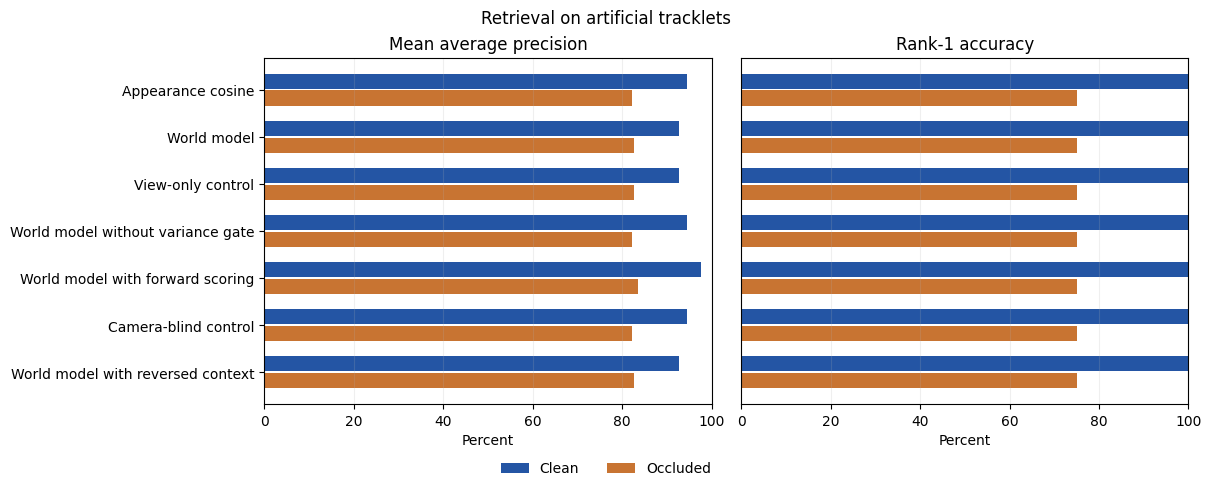

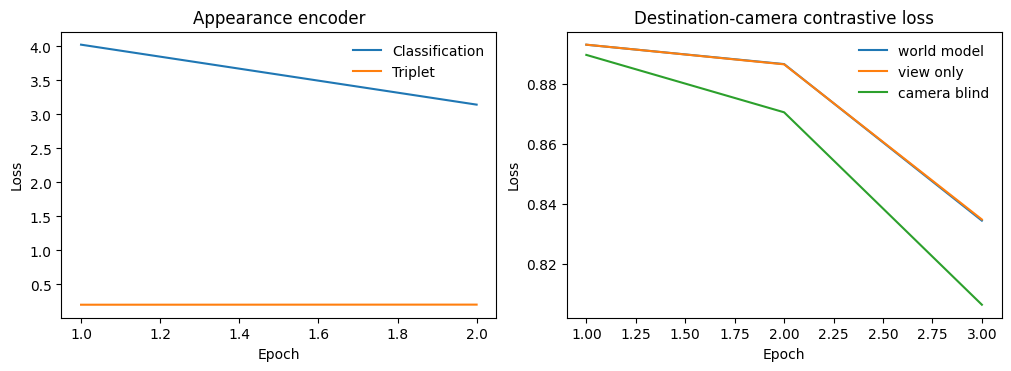

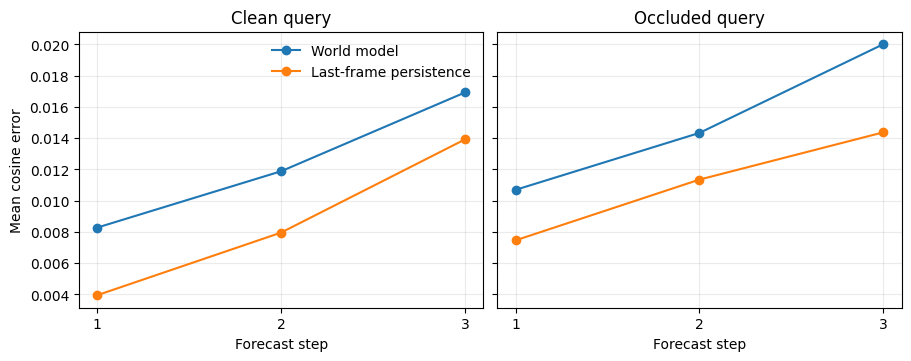

Saved 16 output files to /kaggle/working/camera_world_reid/smoke/seed_42


In [13]:
# 13. Save plots and the settings needed to reproduce the run.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")
colors = ["#2455a4", "#c87432"]
method_names = [trial.name for trial in experiments]
positions = np.arange(len(method_names))
for axis, metric, title in zip(axes, ("mAP", "rank1"), ("Mean average precision", "Rank-1 accuracy")):
    wide = test_metrics.pivot(index="method", columns="query_condition", values=metric)
    for offset, condition, color in zip((-0.18, 0.18), conditions, colors):
        values = wide.loc[method_names, condition].mul(100)
        axis.barh(positions + offset, values, height=0.32, color=color, label=condition.capitalize())
    axis.set(xlabel="Percent", ylabel="", title=title, xlim=(0, 100))
    axis.grid(axis="x", alpha=0.20)
axes[0].set_yticks(positions, method_names)
axes[0].invert_yaxis()
axes[1].tick_params(axis="y", which="both", left=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Retrieval on {split_name}", fontsize=12)
fig.savefig(out_dir / "retrieval_metrics.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
appearance_table = pd.DataFrame(frame_history, columns=["epoch", "total", "classification", "triplet"])
axes[0].plot(appearance_table["epoch"], appearance_table["classification"], label="Classification")
axes[0].plot(appearance_table["epoch"], appearance_table["triplet"], label="Triplet")
axes[0].set(title="Appearance encoder", xlabel="Epoch", ylabel="Loss")
axes[0].legend(frameon=False)
world_table = pd.DataFrame(world_history, columns=[
    "model", "epoch", "total", "view_contrast", "view_nll", "forecast_nll"
])
for name, curve in world_table.groupby("model", sort=False):
    axes[1].plot(curve["epoch"], curve["view_contrast"], label=name.replace("_", " "))
axes[1].set(title="Destination-camera contrastive loss", xlabel="Epoch", ylabel="Loss")
axes[1].legend(frameon=False)
fig.savefig(out_dir / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

if not forecast_details.empty:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True, layout="constrained")
    for axis, condition in zip(axes, conditions):
        subset = forecast_details[forecast_details["query_condition"] == condition]
        for method, curve in subset.groupby("method", sort=False):
            axis.plot(curve["horizon"], curve["mean_cosine_error"], marker="o", label=method)
        axis.set(title=f"{condition.capitalize()} query", xlabel="Forecast step",
                 xticks=list(range(1, cfg.horizon + 1)))
        axis.grid(alpha=0.25)
    axes[0].set_ylabel("Mean cosine error")
    axes[0].legend(frameon=False)
    fig.savefig(out_dir / "forecast_error.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

manifest = {
    "profile": RUN_PROFILE,
    "protocol": split_name,
    "seed": SEED,
    "split_seed": SPLIT_SEED,
    "torch_version": str(torch.__version__),
    "device": str(device),
    "camera_count": camera_count,
    "settings": asdict(cfg),
    "selected_alpha": selected_alpha,
    "train_identities": sorted(train_ids),
    "validation_identities": sorted(val_ids),
    "test_query_tracklets": list(test_q.keys),
    "test_gallery_tracklets": len(test_g.keys),
    "test_gallery_distractors": int((test_g.pids == 0).sum()),
}
(out_dir / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(f"Saved {len(list(out_dir.glob('*')))} output files to {out_dir}")


## 14. Interpret a research run

- The primary comparison is world model versus the matched view-only control on test mAP. The paired bootstrap resamples query identities and gives a 95% interval for the difference, conditional on a trained model and fixed gallery. Report both clean and occluded results.
- Inspect the forecast error against last-frame persistence at each horizon. Better forecast error alone establishes predictive skill on frame latents. The retrieval comparison tests whether that skill helps recover identities. If validation picks $\alpha=0$, the selected ranking is the appearance baseline.
- A world model that helps under reversal may be relying on static appearance. Interpret reversal alongside the matched training control and the persistence test. The occlusion evaluation simulates partial occlusion in the input crops and should be reported as a synthetic stress test.
- For a paper, run multiple training seeds with the same identity split, and report mean and variability. Compare with a stronger video ReID baseline under the same frame budget, for example [TCViT, AAAI 2024](https://doi.org/10.1609/aaai.v38i6.28424). Full-track published scores use different amounts of evidence. MARS uses a fixed camera network, so generalization to unseen cameras or datasets requires another experiment.

**Verification.** The code ran end to end on CPU with synthetic tracklets and with both extracted and ZIP-based MARS-format fixtures. The split loader was also checked against the official MARS metadata. The full MARS image training and Kaggle GPU run remain to be measured.

**Dataset citation.** Zheng et al., [MARS: A Video Benchmark for Large-Scale Person Re-identification](https://www.microsoft.com/en-us/research/publication/mars-video-benchmark-large-scale-person-re-identification/), ECCV 2016.
